In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

# Coarse temperature scan for L=40/60/80/100

According to Morten's notes, what we are looking for: For the two-dimensional case, we move from a phase with finite magnetization ⟨M⟩ ̸=0 to a paramagnetic phase with ⟨M⟩=0 at a critical temperature TC. At the critical temperature, quantities like the heat capacity CV and the susceptibility χ are discontinuous or diverge at the critical point in the thermodynamic limit, i.e., with an infinitely large lattice (citation: Morten's lecture notes, will cite more properly in report)

So in my graphs I'm looking for the magnetisation going to zero, and the two fancy quantities diverging or so.

In [2]:
L = [40, 60, 80, 100]

output = pd.DataFrame(columns=['L', 'temp', 'mean epsilon', 'mean mag', 'CV', 'Xi'])

for i in range(len(L)):
    l = L[i]

    for temp in np.arange(2.10, 2.4, 0.03):
        #Read in files based on temp, needs some rounding
        t = format(temp,'.2f')
        filepath = f'..\Outputs\Phase transitions coarse\PhaseTrans_L{l}_T{t}0000_unordered_n10e6.txt'
        data = pd.read_csv(filepath)

        #Compute quantities of interest
        exp_e = data['epsilon'].mean()
        exp_m = data[' abs(m)'].mean()
        data['epsilon squared'] = data['epsilon']*data['epsilon']
        data['mag squared'] = data[' abs(m)']*data[' abs(m)']
        CV = np.square(l)*(1/np.square(temp))*(data['epsilon squared'].mean() - np.square(exp_e))
        Xi = np.square(l)*(1/temp)*(data['mag squared'].mean() - np.square(exp_m))

        #Write to df
        new =  pd.DataFrame([{'L': l, 'temp': temp, 'mean epsilon': exp_e, 'mean mag': exp_m, 'CV': CV, 'Xi': Xi}])
        output = pd.concat([output, new], ignore_index=True)

<>:11: SyntaxWarning: invalid escape sequence '\O'
<>:11: SyntaxWarning: invalid escape sequence '\O'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_7452\2905818211.py:11: SyntaxWarning: invalid escape sequence '\O'
  filepath = f'..\Outputs\Phase transitions coarse\PhaseTrans_L{l}_T{t}0000_unordered_n10e6.txt'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_7452\2905818211.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, new], ignore_index=True)


In [3]:
L40 = output[output['L']==40]
L60 = output[output['L']==60]
L80 = output[output['L']==80]
L100 = output[output['L']==100]

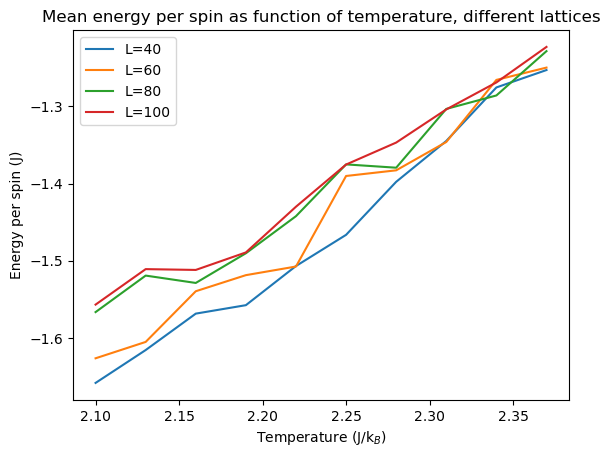

In [4]:
plt.plot(L40['temp'], L40['mean epsilon'], label='L=40')
plt.plot(L60['temp'], L60['mean epsilon'], label='L=60')
plt.plot(L80['temp'], L80['mean epsilon'], label='L=80')
plt.plot(L100['temp'], L100['mean epsilon'], label='L=100')
plt.title('Mean energy per spin as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
plt.ylabel('Energy per spin (J)')
plt.legend()

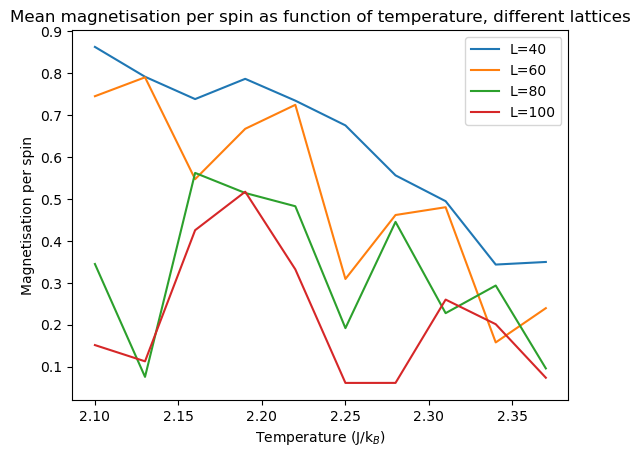

In [5]:
plt.plot(L40['temp'], L40['mean mag'], label='L=40')
plt.plot(L60['temp'], L60['mean mag'], label='L=60')
plt.plot(L80['temp'], L80['mean mag'], label='L=80')
plt.plot(L100['temp'], L100['mean mag'], label='L=100')
plt.title('Mean magnetisation per spin as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
plt.ylabel('Magnetisation per spin')
plt.legend()
plt.savefig('Magnetisation phase transitions, coarse scan.pdf')

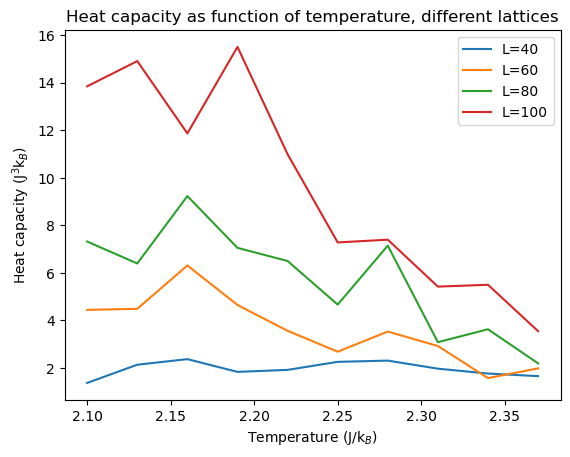

In [6]:
plt.plot(L40['temp'], L40['CV'], label='L=40')
plt.plot(L60['temp'], L60['CV'], label='L=60')
plt.plot(L80['temp'], L80['CV'], label='L=80')
plt.plot(L100['temp'], L100['CV'], label='L=100')
plt.title('Heat capacity as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
plt.ylabel(r'Heat capacity (J$^3$k$_B$)')
plt.legend()

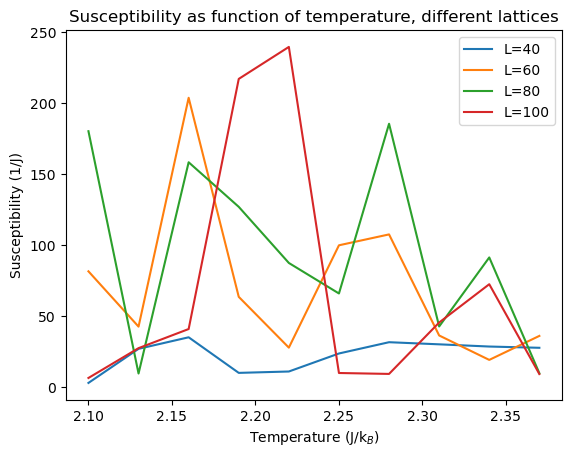

In [7]:
plt.plot(L40['temp'], L40['Xi'], label='L=40')
plt.plot(L60['temp'], L60['Xi'], label='L=60')
plt.plot(L80['temp'], L80['Xi'], label='L=80')
plt.plot(L100['temp'], L100['Xi'], label='L=100')
plt.title('Susceptibility as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
plt.ylabel('Susceptibility (1/J)')
plt.legend()
plt.savefig('Susceptibility phase transitions, coarse scan.pdf')

Looking mostly at mag, I'd say that my candidates are:

- 2.12-2.15

- 2.15-2.18

- 2.22-2.28

Run these with a step size of 0.003, should give me about 10 steps for each (can do the first two together).

# Phase transitions more finely spaced, T=2.12-2.18

In [9]:
L = [40, 60, 80, 100]

output = pd.DataFrame(columns=['L', 'temp', 'mean epsilon', 'mean mag', 'CV', 'Xi'])

for i in range(len(L)):
    l = L[i]

    for temp in np.arange(2.12, 2.189, 0.003):
        #Read in files based on temp, needs some rounding
        t = format(temp,'.3f')
        filepath = f'..\Outputs\Phase transitions fine\PhaseTrans_L{l}_T{t}000_unordered_n10e6.txt'
        data = pd.read_csv(filepath)

        #Compute quantities of interest
        exp_e = data['epsilon'].mean()
        exp_m = data[' abs(m)'].mean()
        data['epsilon squared'] = data['epsilon']*data['epsilon']
        data['mag squared'] = data[' abs(m)']*data[' abs(m)']
        CV = np.square(l)*(1/np.square(temp))*(data['epsilon squared'].mean() - np.square(exp_e))
        Xi = np.square(l)*(1/temp)*(data['mag squared'].mean() - np.square(exp_m))

        #Write to df
        new =  pd.DataFrame([{'L': l, 'temp': temp, 'mean epsilon': exp_e, 'mean mag': exp_m, 'CV': CV, 'Xi': Xi}])
        output = pd.concat([output, new], ignore_index=True)

<>:11: SyntaxWarning: invalid escape sequence '\O'
<>:11: SyntaxWarning: invalid escape sequence '\O'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\2098983603.py:11: SyntaxWarning: invalid escape sequence '\O'
  filepath = f'..\Outputs\Phase transitions fine\PhaseTrans_L{l}_T{t}000_unordered_n10e6.txt'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\2098983603.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, new], ignore_index=True)


C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\4099191005.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  L40['Xi'] = L40['Xi']/np.max(L40['Xi'])
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\4099191005.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  L60['Xi'] = L60['Xi']/np.max(L60['Xi'])
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\4099191005.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value

70    2.123
74    2.135
78    2.147
84    2.165
90    2.183
Name: temp, dtype: float64


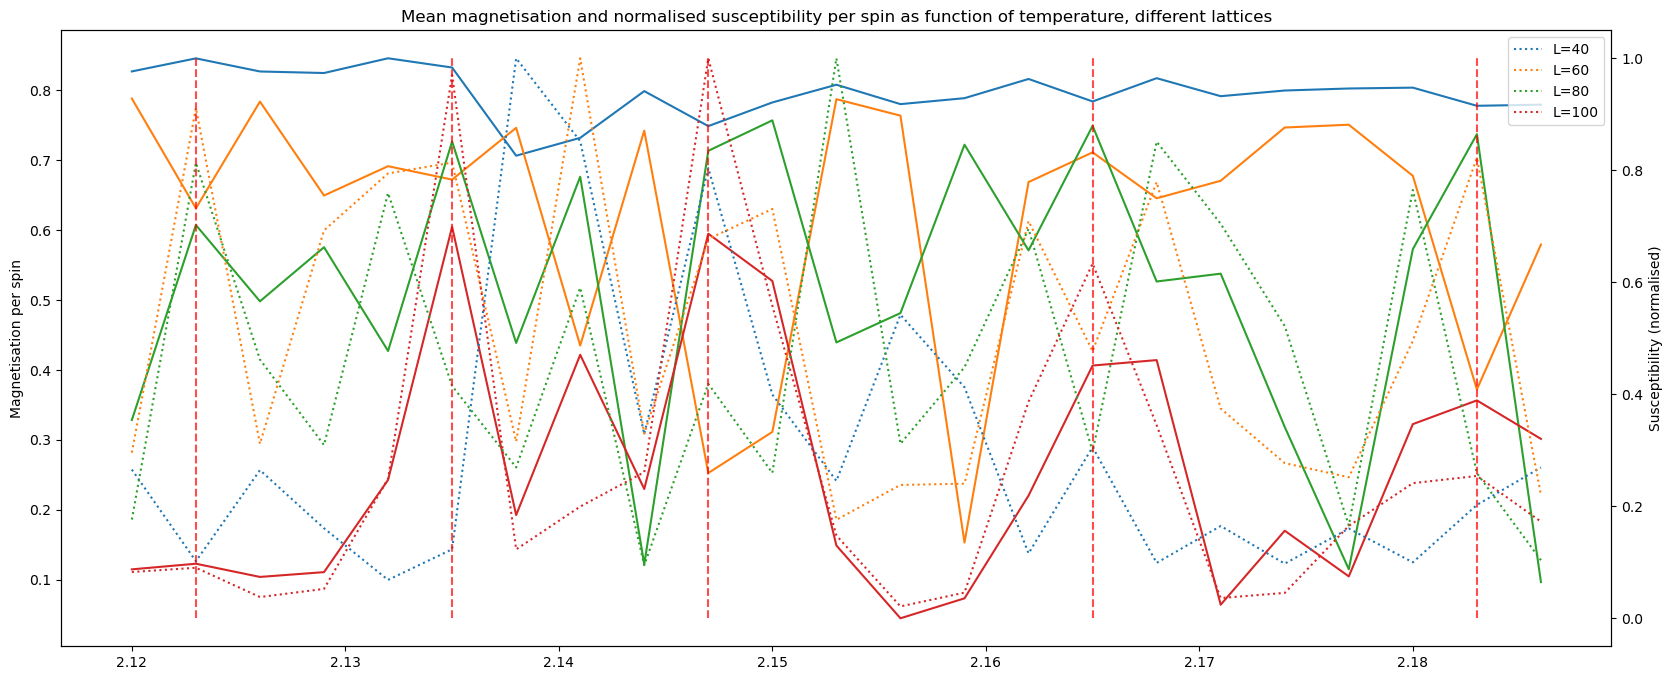

In [10]:
L40 = output[output['L']==40]
L40['Xi'] = L40['Xi']/np.max(L40['Xi'])
L60 = output[output['L']==60]
L60['Xi'] = L60['Xi']/np.max(L60['Xi'])
L80 = output[output['L']==80]
L80['Xi'] = L80['Xi']/np.max(L80['Xi'])
L100 = output[output['L']==100]
L100['Xi'] = L100['Xi']/np.max(L100['Xi'])

fig, ax1 = plt.subplots(figsize=(20, 8))

ax1.plot(L40['temp'], L40['mean mag'], label='L=40')
ax1.plot(L60['temp'], L60['mean mag'], label='L=60')
ax1.plot(L80['temp'], L80['mean mag'], label='L=80')
ax1.plot(L100['temp'], L100['mean mag'], label='L=100')

ax2 = ax1.twinx()

ax2.plot(L40['temp'], L40['Xi'], label='L=40', linestyle=':')
ax2.plot(L60['temp'], L60['Xi'], label='L=60', linestyle=':')
ax2.plot(L80['temp'], L80['Xi'], label='L=80', linestyle=':')
ax2.plot(L100['temp'], L100['Xi'], label='L=100', linestyle=':')

localmaxima, _ = find_peaks(L100['Xi'])
ax2.vlines(L100['temp'].iloc[localmaxima], 0, 1, colors='red', linestyles='--', alpha=0.7)
print(L100['temp'].iloc[localmaxima])


plt.title('Mean magnetisation and normalised susceptibility per spin as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
ax1.set_ylabel('Magnetisation per spin')
ax2.set_ylabel('Susceptibility (normalised)')
plt.legend()
plt.savefig('L100_possibletransitions_part1.pdf')

# More finely spaced, T=2.19 - 2.213

In [11]:
L = [40, 60, 80, 100]

output = pd.DataFrame(columns=['L', 'temp', 'mean epsilon', 'mean mag', 'CV', 'Xi'])

for i in range(len(L)):
    l = L[i]

    for temp in np.arange(2.192, 2.213, 0.003):
        #Read in files based on temp, needs some rounding
        t = format(temp,'.3f')
        filepath = f'..\Outputs\Phase transitions fine\PhaseTrans_L{l}_T{t}000_unordered_n10e6.txt'
        data = pd.read_csv(filepath)

        #Compute quantities of interest
        exp_e = data['epsilon'].mean()
        exp_m = data[' abs(m)'].mean()
        data['epsilon squared'] = data['epsilon']*data['epsilon']
        data['mag squared'] = data[' abs(m)']*data[' abs(m)']
        CV = np.square(l)*(1/np.square(temp))*(data['epsilon squared'].mean() - np.square(exp_e))
        Xi = np.square(l)*(1/temp)*(data['mag squared'].mean() - np.square(exp_m))

        #Write to df
        new =  pd.DataFrame([{'L': l, 'temp': temp, 'mean epsilon': exp_e, 'mean mag': exp_m, 'CV': CV, 'Xi': Xi}])
        output = pd.concat([output, new], ignore_index=True)

<>:11: SyntaxWarning: invalid escape sequence '\O'
<>:11: SyntaxWarning: invalid escape sequence '\O'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\659594314.py:11: SyntaxWarning: invalid escape sequence '\O'
  filepath = f'..\Outputs\Phase transitions fine\PhaseTrans_L{l}_T{t}000_unordered_n10e6.txt'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\659594314.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, new], ignore_index=True)


C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\513527246.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  L40['Xi'] = L40['Xi']/np.max(L40['Xi'])
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\513527246.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  L60['Xi'] = L60['Xi']/np.max(L60['Xi'])
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\513527246.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value in

22    2.195
25    2.204
Name: temp, dtype: float64


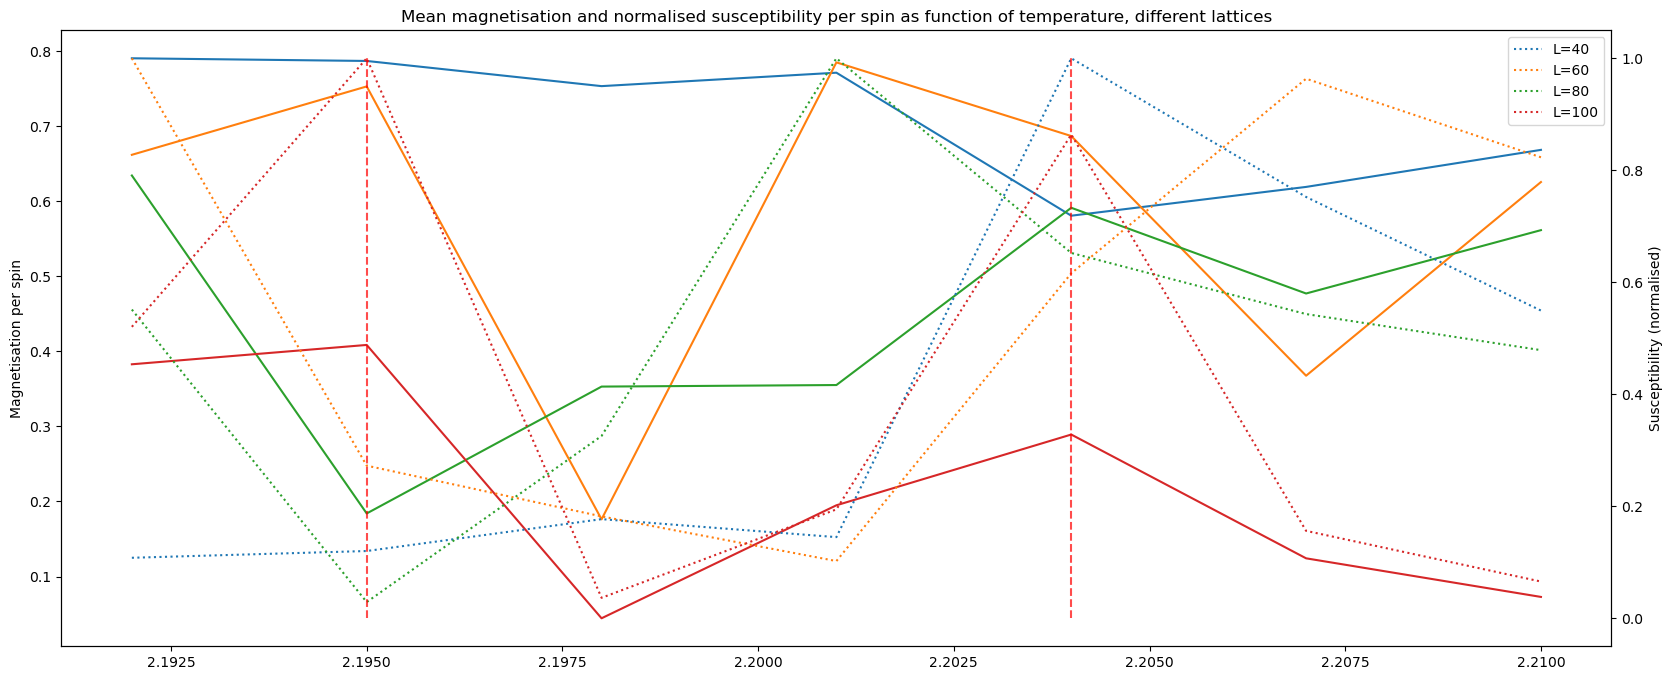

In [12]:
L40 = output[output['L']==40]
L40['Xi'] = L40['Xi']/np.max(L40['Xi'])
L60 = output[output['L']==60]
L60['Xi'] = L60['Xi']/np.max(L60['Xi'])
L80 = output[output['L']==80]
L80['Xi'] = L80['Xi']/np.max(L80['Xi'])
L100 = output[output['L']==100]
L100['Xi'] = L100['Xi']/np.max(L100['Xi'])

fig, ax1 = plt.subplots(figsize=(20, 8))

ax1.plot(L40['temp'], L40['mean mag'], label='L=40')
ax1.plot(L60['temp'], L60['mean mag'], label='L=60')
ax1.plot(L80['temp'], L80['mean mag'], label='L=80')
ax1.plot(L100['temp'], L100['mean mag'], label='L=100')

ax2 = ax1.twinx()

ax2.plot(L40['temp'], L40['Xi'], label='L=40', linestyle=':')
ax2.plot(L60['temp'], L60['Xi'], label='L=60', linestyle=':')
ax2.plot(L80['temp'], L80['Xi'], label='L=80', linestyle=':')
ax2.plot(L100['temp'], L100['Xi'], label='L=100', linestyle=':')

localmaxima, _ = find_peaks(L100['Xi'])
ax2.vlines(L100['temp'].iloc[localmaxima], 0, 1, colors='red', linestyles='--', alpha=0.7)
print(L100['temp'].iloc[localmaxima])


plt.title('Mean magnetisation and normalised susceptibility per spin as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
ax1.set_ylabel('Magnetisation per spin')
ax2.set_ylabel('Susceptibility (normalised)')
plt.legend()
plt.savefig('L100_possibletransitions_part2.pdf')

# More finely spaced, T=2.22-2.28

In [13]:
L = [40, 60, 80, 100]

output = pd.DataFrame(columns=['L', 'temp', 'mean epsilon', 'mean mag', 'CV', 'Xi'])

for i in range(len(L)):
    l = L[i]

    for temp in np.arange(2.22, 2.283, 0.003):
        #Read in files based on temp, needs some rounding
        t = format(temp,'.3f')
        filepath = f'..\Outputs\Phase transitions fine\PhaseTrans_L{l}_T{t}000_unordered_n10e6.txt'
        data = pd.read_csv(filepath)

        #Compute quantities of interest
        exp_e = data['epsilon'].mean()
        exp_m = data[' abs(m)'].mean()
        data['epsilon squared'] = data['epsilon']*data['epsilon']
        data['mag squared'] = data[' abs(m)']*data[' abs(m)']
        CV = np.square(l)*(1/np.square(temp))*(data['epsilon squared'].mean() - np.square(exp_e))
        Xi = np.square(l)*(1/temp)*(data['mag squared'].mean() - np.square(exp_m))

        #Write to df
        new =  pd.DataFrame([{'L': l, 'temp': temp, 'mean epsilon': exp_e, 'mean mag': exp_m, 'CV': CV, 'Xi': Xi}])
        output = pd.concat([output, new], ignore_index=True)

<>:11: SyntaxWarning: invalid escape sequence '\O'
<>:11: SyntaxWarning: invalid escape sequence '\O'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\1320043030.py:11: SyntaxWarning: invalid escape sequence '\O'
  filepath = f'..\Outputs\Phase transitions fine\PhaseTrans_L{l}_T{t}000_unordered_n10e6.txt'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\1320043030.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, new], ignore_index=True)


C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\2339058813.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  L40['Xi'] = L40['Xi']/np.max(L40['Xi'])
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\2339058813.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  L60['Xi'] = L60['Xi']/np.max(L60['Xi'])
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\2339058813.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value

64    2.223
66    2.229
69    2.238
71    2.244
75    2.256
77    2.262
82    2.277
Name: temp, dtype: float64


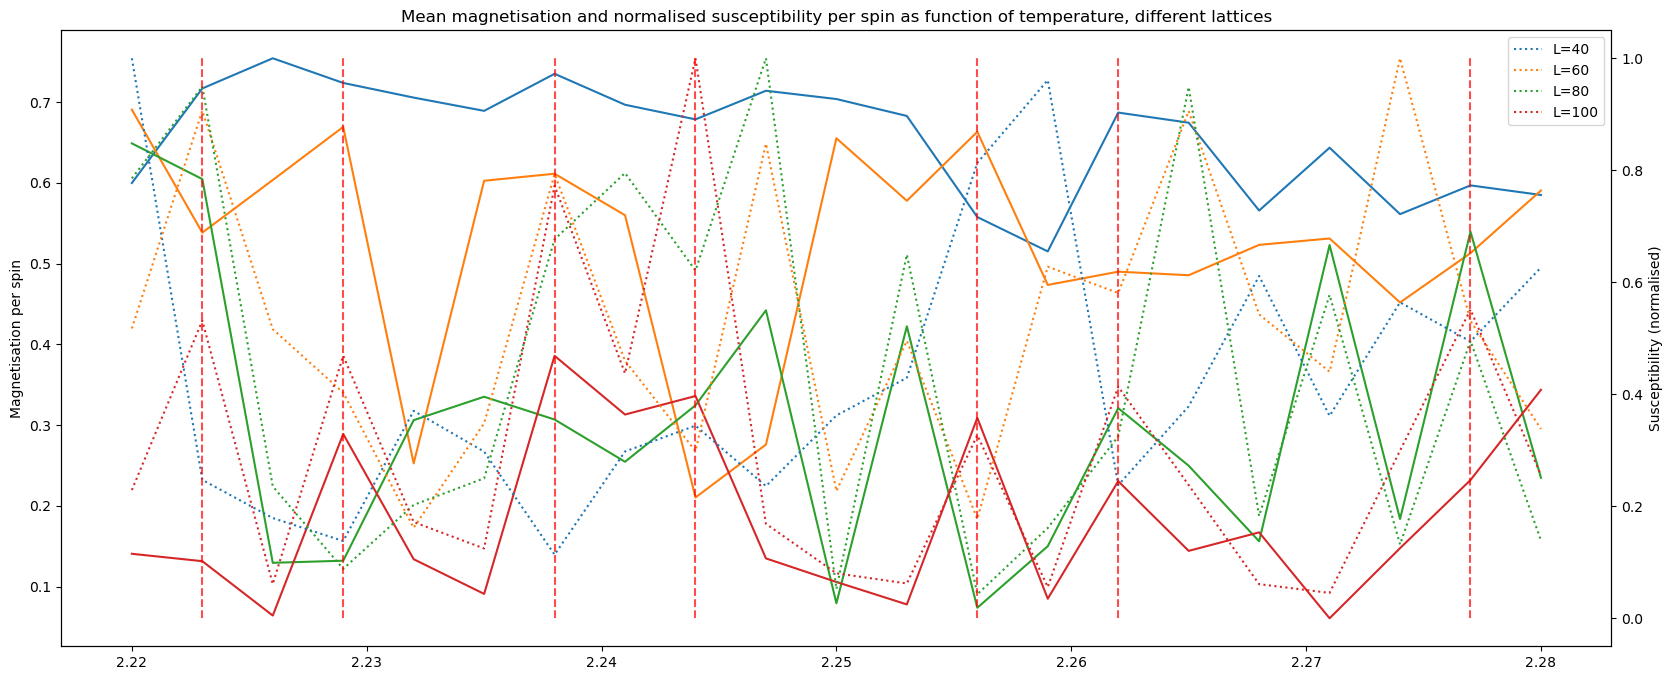

In [14]:
L40 = output[output['L']==40]
L40['Xi'] = L40['Xi']/np.max(L40['Xi'])
L60 = output[output['L']==60]
L60['Xi'] = L60['Xi']/np.max(L60['Xi'])
L80 = output[output['L']==80]
L80['Xi'] = L80['Xi']/np.max(L80['Xi'])
L100 = output[output['L']==100]
L100['Xi'] = L100['Xi']/np.max(L100['Xi'])

fig, ax1 = plt.subplots(figsize=(20, 8))

ax1.plot(L40['temp'], L40['mean mag'], label='L=40')
ax1.plot(L60['temp'], L60['mean mag'], label='L=60')
ax1.plot(L80['temp'], L80['mean mag'], label='L=80')
ax1.plot(L100['temp'], L100['mean mag'], label='L=100')

ax2 = ax1.twinx()

ax2.plot(L40['temp'], L40['Xi'], label='L=40', linestyle=':')
ax2.plot(L60['temp'], L60['Xi'], label='L=60', linestyle=':')
ax2.plot(L80['temp'], L80['Xi'], label='L=80', linestyle=':')
ax2.plot(L100['temp'], L100['Xi'], label='L=100', linestyle=':')

localmaxima, _ = find_peaks(L100['Xi'])
ax2.vlines(L100['temp'].iloc[localmaxima], 0, 1, colors='red', linestyles='--', alpha=0.7)
print(L100['temp'].iloc[localmaxima])


plt.title('Mean magnetisation and normalised susceptibility per spin as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
ax1.set_ylabel('Magnetisation per spin')
ax2.set_ylabel('Susceptibility (normalised)')
plt.legend()
plt.savefig('L100_possibletransitions_part3.pdf')

# Even finer grid 2.23-2.25 to really be sure

In [15]:
L = [40, 60, 80, 100]

output = pd.DataFrame(columns=['L', 'temp', 'mean epsilon', 'mean mag', 'CV', 'Xi'])

for i in range(len(L)):
    l = L[i]

    for temp in np.arange(2.23, 2.249, 0.003):
        #Read in files based on temp, needs some rounding
        t = format(temp,'.3f')
        filepath = f'..\Outputs\VERYFINESEARCH\PhaseTrans_L{l}_T{t}000_unordered_n10e6.txt'
        data = pd.read_csv(filepath)

        #Compute quantities of interest
        exp_e = data['epsilon'].mean()
        exp_m = data[' abs(m)'].mean()
        data['epsilon squared'] = data['epsilon']*data['epsilon']
        data['mag squared'] = data[' abs(m)']*data[' abs(m)']
        CV = np.square(l)*(1/np.square(temp))*(data['epsilon squared'].mean() - np.square(exp_e))
        Xi = np.square(l)*(1/temp)*(data['mag squared'].mean() - np.square(exp_m))

        #Write to df
        new =  pd.DataFrame([{'L': l, 'temp': temp, 'mean epsilon': exp_e, 'mean mag': exp_m, 'CV': CV, 'Xi': Xi}])
        output = pd.concat([output, new], ignore_index=True)

<>:11: SyntaxWarning: invalid escape sequence '\O'
<>:11: SyntaxWarning: invalid escape sequence '\O'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\2945747049.py:11: SyntaxWarning: invalid escape sequence '\O'
  filepath = f'..\Outputs\VERYFINESEARCH\PhaseTrans_L{l}_T{t}000_unordered_n10e6.txt'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\2945747049.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, new], ignore_index=True)


C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\59832794.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  L40['Xi'] = L40['Xi']/np.max(L40['Xi'])
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\59832794.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  L60['Xi'] = L60['Xi']/np.max(L60['Xi'])
C:\Users\bhaan\AppData\Local\Temp\ipykernel_16848\59832794.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inste

1    2.233
3    2.239
5    2.245
Name: temp, dtype: float64
12    2.245
Name: temp, dtype: float64
17    2.239
19    2.245
Name: temp, dtype: float64
23    2.236
Name: temp, dtype: float64


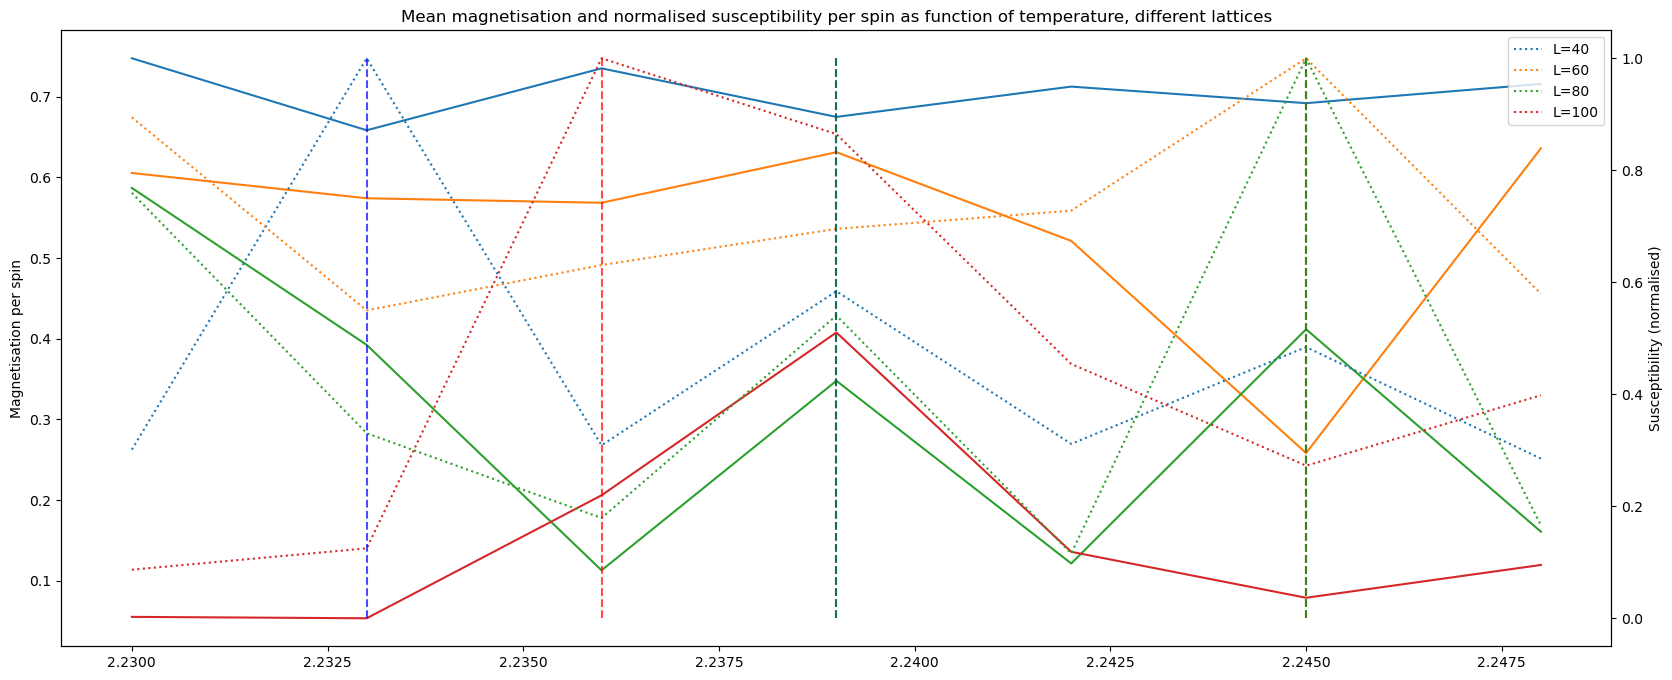

In [20]:
L40 = output[output['L']==40]
L40['Xi'] = L40['Xi']/np.max(L40['Xi'])
L60 = output[output['L']==60]
L60['Xi'] = L60['Xi']/np.max(L60['Xi'])
L80 = output[output['L']==80]
L80['Xi'] = L80['Xi']/np.max(L80['Xi'])
L100 = output[output['L']==100]
L100['Xi'] = L100['Xi']/np.max(L100['Xi'])

fig, ax1 = plt.subplots(figsize=(20, 8))

ax1.plot(L40['temp'], L40['mean mag'], label='L=40')
ax1.plot(L60['temp'], L60['mean mag'], label='L=60')
ax1.plot(L80['temp'], L80['mean mag'], label='L=80')
ax1.plot(L100['temp'], L100['mean mag'], label='L=100')

ax2 = ax1.twinx()

ax2.plot(L40['temp'], L40['Xi'], label='L=40', linestyle=':')
ax2.plot(L60['temp'], L60['Xi'], label='L=60', linestyle=':')
ax2.plot(L80['temp'], L80['Xi'], label='L=80', linestyle=':')
ax2.plot(L100['temp'], L100['Xi'], label='L=100', linestyle=':')

localmaxima, _ = find_peaks(L40['Xi'])
ax2.vlines(L40['temp'].iloc[localmaxima], 0, 1, colors='blue', linestyles='--', alpha=0.7)
print(L40['temp'].iloc[localmaxima])

localmaxima, _ = find_peaks(L60['Xi'])
ax2.vlines(L60['temp'].iloc[localmaxima], 0, 1, colors='orange', linestyles='--', alpha=0.7)
print(L60['temp'].iloc[localmaxima])

localmaxima, _ = find_peaks(L80['Xi'])
ax2.vlines(L80['temp'].iloc[localmaxima], 0, 1, colors='green', linestyles='--', alpha=0.7)
print(L80['temp'].iloc[localmaxima])

localmaxima, _ = find_peaks(L100['Xi'])
ax2.vlines(L100['temp'].iloc[localmaxima], 0, 1, colors='red', linestyles='--', alpha=0.7)
print(L100['temp'].iloc[localmaxima])


plt.title('Mean magnetisation and normalised susceptibility per spin as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
ax1.set_ylabel('Magnetisation per spin')
ax2.set_ylabel('Susceptibility (normalised)')
plt.legend()
plt.savefig('Possibletransitions_mostdetailed.pdf')

# Estimate T_c for L=inf

In [11]:
def func(linv, a, tcinf):
    return a*linv + tcinf

#Tc values that I found from reading off the plots
Tc = [2.232, 2.238, 2.241, 2.244]
Linv = [0, 0, 0, 0]
for i in range(len(L)):
    Linv[i] = 1/L[i]

#Curve fitting + errors snippet obtained from https://www.statsmodels.org/devel/examples/notebooks/generated/chi2_fitting.html
popt, pcov = curve_fit(func, Linv, Tc, [0, 0])
perr = np.sqrt(np.diag(pcov))
print(f"a = {popt[0]:10.3f} +- {perr[0]:10.3f}")
print(f"Tinf = {popt[1]:10.3f} +- {perr[1]:10.3f}")

a =     -0.776 +-      0.051
Tinf =      2.251 +-      0.001


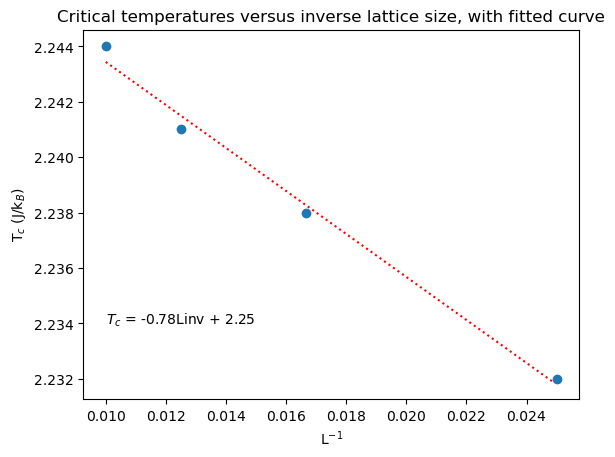

In [12]:
plt.scatter(Linv, Tc, label=r'T$_c$ identified from simulations')
plt.plot(np.arange(0.01, 0.025, 0.0001), func(np.arange(0.01, 0.025, 0.0001), popt[0], popt[1]), linestyle=':', color='red', label='curve fit')
plt.title('Critical temperatures versus inverse lattice size, with fitted curve')
plt.xlabel(r'L$^{-1}$')
plt.ylabel('T$_c$ (J/k$_B$)')
plt.text(0.01, 2.234, rf'$T_c$ = {round(popt[0],2)}Linv + {round(popt[1],2)}')
plt.savefig('Inverse lattice and critical temp fit.pdf')